<a href="https://colab.research.google.com/github/prernakkjaiswal/AD-H-web-development-/blob/main/CROP_PREDICTION.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("abdallahalidev/plantvillage-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'plantvillage-dataset' dataset.
Path to dataset files: /kaggle/input/plantvillage-dataset


In [ ]:
link="https://www.kaggle.com/datasets/abdallahalidev/plantvillage-dataset"

In [ ]:
import pandas as pd


# New section

In [ ]:

import tensorflow as tf
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

In [ ]:

import os

# List contents of the downloaded dataset directory
print("Contents of the dataset directory:")
for item in os.listdir(path):
    item_path = os.path.join(path, item)
    if os.path.isdir(item_path):
        print(f"Directory: {item} (contains {len(os.listdir(item_path))} items)")
    else:
        print(f"File: {item}")

Contents of the dataset directory:
Directory: plantvillage dataset (contains 3 items)


Once we see the names of the directories (for example, there might be a nested `plantvillage dataset` folder, or folders named `color`, `grayscale`, `segmented`), we can use the correct directory path in `image_dataset_from_directory` instead of a relative string like `'training'`.

In [ ]:

import os
import tensorflow as tf

# Define the target image directory
# The dataset has subfolders: 'color', 'grayscale', 'segmented' inside 'plantvillage dataset'
data_dir = os.path.join(path, "plantvillage dataset", "color")

# Load the training dataset
training_set = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    labels='inferred',
    label_mode='categorical',
    color_mode='rgb',
    batch_size=32,
    image_size=(128, 128),
    shuffle=True,
    seed=42,
    validation_split=0.2,
    subset='training'
)

# Load the validation dataset
validation_set = tf.keras.utils.image_dataset_from_directory(
    data_dir,
    labels='inferred',
    label_mode='categorical',
    color_mode='rgb',
    batch_size=32,
    image_size=(128, 128),
    shuffle=True,
    seed=42,
    validation_split=0.2,
    subset='validation'
)

Found 54305 files belonging to 38 classes.
Using 43444 files for training.
Found 54305 files belonging to 38 classes.
Using 10861 files for validation.


In [ ]:
training_set

<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 38), dtype=tf.float32, name=None))>

In [ ]:
validation_set

<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None, 38), dtype=tf.float32, name=None))>

In [ ]:
for x,y in training_set:
  print(x,x.shape)
  print(y,y.shape)
  break

tf.Tensor(
[[[[152.5  145.5  153.5 ]
   [171.5  164.5  172.5 ]
   [163.25 156.25 164.25]
   ...
   [171.25 160.25 168.25]
   [169.25 158.25 166.25]
   [165.25 154.25 162.25]]

  [[158.25 151.25 159.25]
   [190.5  183.5  191.5 ]
   [171.25 164.25 172.25]
   ...
   [161.   150.   158.  ]
   [165.   154.   162.  ]
   [164.25 153.25 161.25]]

  [[165.25 158.25 166.25]
   [166.75 159.75 167.75]
   [177.25 170.25 178.25]
   ...
   [162.5  151.5  159.5 ]
   [163.75 152.75 160.75]
   [161.5  150.5  158.5 ]]

  ...

  [[170.75 155.75 160.75]
   [172.5  157.5  162.5 ]
   [172.25 157.25 162.25]
   ...
   [166.25 152.25 152.25]
   [157.   143.   143.  ]
   [169.5  155.5  155.5 ]]

  [[162.75 147.75 152.75]
   [164.5  149.5  154.5 ]
   [171.   156.   161.  ]
   ...
   [167.75 153.75 153.75]
   [156.5  142.5  142.5 ]
   [161.25 147.25 147.25]]

  [[172.25 157.25 162.25]
   [167.25 152.25 157.25]
   [172.5  157.5  162.5 ]
   ...
   [159.   145.   145.  ]
   [157.75 143.75 143.75]
   [164.25 150.25 15

#TO AVOID OVERSHOOTING
1. choose small learnig rate derfault is  0.001(we choose 0.0001)
2. there may be chance of underfitting, so increase no. of neuron
3. add more Convolution layer to extract more feature from images there may be possibilty that model unable to capture relevant model is confusing due to lack of feature so feed it more features


In [ ]:
#BUILDING MODEL

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Conv2D, Flatten, MaxPooling2D,Dropout

In [ ]:
model=Sequential()

In [ ]:
model.add(Conv2D(filters=32, kernel_size=3, padding='same',activation='relu',input_shape=(128,128,3)))
model.add(Conv2D(filters=32, kernel_size=3,activation='relu'))
model.add(MaxPooling2D(pool_size=2,strides=2))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.add(Conv2D(filters=64, kernel_size=3, padding='same',activation='relu',input_shape=(128,128,3)))
model.add(Conv2D(filters=64, kernel_size=3,activation='relu'))
model.add(MaxPooling2D(pool_size=2,strides=2))

In [ ]:
model.add(Conv2D(filters=128, kernel_size=3, padding='same', activation='relu'))
model.add(Conv2D(filters=128, kernel_size=3,  activation='relu'))
model.add(MaxPooling2D(pool_size=2, strides=2))

In [ ]:
model.add(Conv2D(filters=256, kernel_size=3, padding='same', activation='relu'))
model.add(Conv2D(filters=256, kernel_size=3,  activation='relu'))
model.add(MaxPooling2D(pool_size=2, strides=2))

In [ ]:
model.add(Conv2D(filters=512, kernel_size=3, padding='same', activation='relu'))
model.add(Conv2D(filters=512, kernel_size=3,activation='relu'))
model.add(MaxPooling2D(pool_size=2, strides=2))

In [ ]:
model.add(Dropout(0.25))   # to avoid overfitting

In [ ]:
model.add(Flatten())

In [ ]:
model.add(Dropout(0.4))

In [ ]:

model.add(Dense(units=1500,activation='relu'))

In [ ]:
#Output layer
model.add(Dense(units=38,activation='softmax'))

  COMPILING MODEL

In [ ]:
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),loss='categorical_crossentropy',metrics=['accuracy'])

In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 126, 126, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 63, 63, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 61, 61, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 30, 30, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 14, 14, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 12, 12, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 6, 6, 512)      │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 4, 4, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 2, 2, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2, 2, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1500)           │     3,073,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 38)             │        57,038 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,842,762 (29.92 MB)

 Trainable params: 7,842,762 (29.92 MB)

 Non-trainable params: 0 (0.00 B)

MODEL TRAINING

In [ ]:
training_history=model.fit(x=training_set, validation_data=validation_set,epochs=15)

Epoch 1/15
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 317s 212ms/step - accuracy: 0.6040 - loss: 1.3788 - val_accuracy: 0.8070 - val_loss: 0.6330
Epoch 2/15
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 91s 67ms/step - accuracy: 0.8280 - loss: 0.5455 - val_accuracy: 0.8817 - val_loss: 0.3631
Epoch 3/15
1131/1358 ━━━━━━━━━━━━━━━━━━━━ 13s 58ms/step - accuracy: 0.8802 - loss: 0.3902

MODEL EVALUTION

In [ ]:
#model evaluation on training set
train_loss, train_acc= model.evaluate(training_set)

1358/1358 ━━━━━━━━━━━━━━━━━━━━ 56s 41ms/step - accuracy: 0.9941 - loss: 0.0184


In [ ]:
print("Training_loss:",train_loss)
print("trainig acccuracy:",train_acc)

Training_loss: 0.018423663452267647
trainig acccuracy: 0.994061291217804


In [ ]:
#model evaluation on validation set
valid_loss, valid_acc= model.evaluate(validation_set)

340/340 ━━━━━━━━━━━━━━━━━━━━ 14s 41ms/step - accuracy: 0.9653 - loss: 0.1335


In [ ]:
print("Validation_loss:",valid_loss)
print("validation acccuracy:",valid_acc)

Validation_loss: 0.13347779214382172
validation acccuracy: 0.9652886390686035


In [ ]:
model.save("trained_model.h5")

In [ ]:
model.save("trained_modal.keras")

In [ ]:
training_history.history

{'accuracy': [0.5820136070251465,
  0.8190083503723145,
  0.8829757571220398,
  0.9136819839477539,
  0.9344443678855896,
  0.9470813274383545,
  0.9560583829879761,
  0.9639075398445129,
  0.9688564538955688,
  0.9727234840393066,
  0.9763603806495667,
  0.9792606830596924,
  0.980365514755249,
  0.9829666018486023,
  0.9833579063415527],
 'loss': [1.4739301204681396,
  0.5771586894989014,
  0.3662760257720947,
  0.26398542523384094,
  0.1977110654115677,
  0.15800729393959045,
  0.13521865010261536,
  0.10679454356431961,
  0.0926620364189148,
  0.08354712277650833,
  0.07250373810529709,
  0.06391356885433197,
  0.05878376588225365,
  0.053223617374897,
  0.05150579288601875],
 'val_accuracy': [0.8003867268562317,
  0.8890525698661804,
  0.9047049283981323,
  0.9252370595932007,
  0.9304852485656738,
  0.9464137554168701,
  0.9535954594612122,
  0.9592118859291077,
  0.9440199136734009,
  0.9500966668128967,
  0.9586594104766846,
  0.953135073184967,
  0.9617899060249329,
  0.968050

In [ ]:
#Recording history in json
import json
with open("training_his.json","w") as f:
  json.dump(training_history.history,f)

## ACCURACY VISUALIZATION

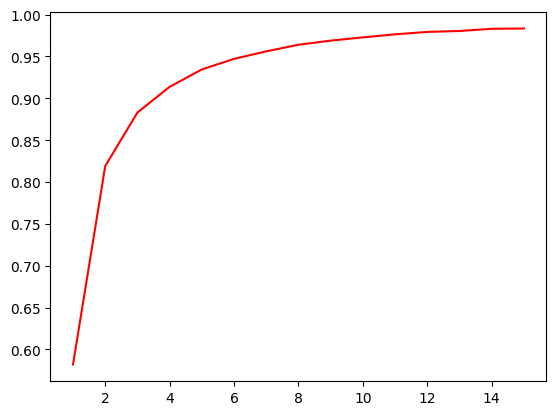

In [ ]:
epochs=[i for i in range(1,16)]
plt.plot(epochs,training_history.history["accuracy"],color='red',label= 'traning accuracy')

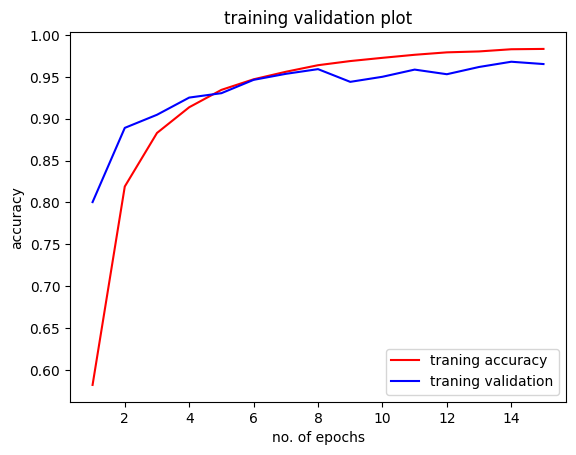

In [ ]:

epochs=[i for i in range(1,16)]
plt.plot(epochs,training_history.history["accuracy"],color='red',label= 'traning accuracy')
epochs=[i for i in range(1,16)]
plt.plot(epochs,training_history.history["val_accuracy"],color='blue',label= 'traning validation')
plt.xlabel("no. of epochs")
plt.ylabel("accuracy")
plt.title("training validation plot")
plt.legend()
plt.show()

In [ ]:
!pip install opendatasets -q
import opendatasets as od

# Download PlantVillage dataset from Kaggle
od.download("https://www.kaggle.com/datasets/abdallahalidev/plantvillage-dataset")

ModuleNotFoundError: No module named 'cgi'

In [ ]:
link='/kaggle/input/plantvillage-dataset/color'

In [ ]:
# Install the split-folders library if you haven't already
!pip install split-folders -q

import splitfolders

# Correct path to the nested color dataset directory
input_folder = '/kaggle/input/plantvillage-dataset/plantvillage dataset/color'

# Destination path in your working directory where folders will be created
output_folder = '/kaggle/working/plantvillage_split'

# Split ratio: 80% Training, 10% Validation, 10% Test
splitfolders.ratio(input_folder, output=output_folder, seed=42, ratio=(0.8, 0.1, 0.1))

print("Dataset successfully split into train, val, and test folders!")

Copying files: 54305 files [02:54, 310.97 files/s]

Dataset successfully split into train, val, and test folders!


In [ ]:
import tensorflow as tf

# Point directly to the test folder in your newly split dataset directory
test_dir = '/kaggle/working/plantvillage_split/test'

test_set = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    labels='inferred',
    label_mode='categorical',
    color_mode='rgb',
    batch_size=32,
    image_size=(128, 128),
    shuffle=False  # Keep False so order matches your evaluation loop
)

class_name = test_set.class_names
print("Test Classes found:", class_name)

Found 5459 files belonging to 38 classes.
Test Classes found: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch', 'Strawberry___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomat

In [ ]:
import os

# Let's see the structure inside 'plantvillage dataset'
base_folder = os.path.join(path, "plantvillage dataset")
print(os.listdir(base_folder))

['segmented', 'grayscale', 'color']


In [ ]:
y_pred= model.predict(test_set)
y_pred,y_pred.shape

171/171 ━━━━━━━━━━━━━━━━━━━━ 12s 67ms/step


(array([[9.8769110e-01, 2.0607265e-06, 6.6883496e-07, ..., 6.4083200e-10,
         3.8129549e-08, 2.5926125e-08],
        [9.9998128e-01, 3.1938461e-09, 4.8024181e-06, ..., 4.0967906e-12,
         3.1075844e-13, 1.8494386e-07],
        [9.9999809e-01, 1.3424705e-06, 1.2192247e-12, ..., 9.8818255e-22,
         3.0792898e-18, 1.0135672e-14],
        ...,
        [1.2025327e-10, 4.9269065e-15, 2.1861393e-11, ..., 1.0807857e-11,
         2.8272172e-12, 1.0000000e+00],
        [2.7584331e-13, 1.7918345e-16, 1.0552188e-13, ..., 1.1479987e-14,
         6.7041400e-15, 1.0000000e+00],
        [2.7054073e-11, 1.4567836e-13, 2.9722012e-13, ..., 2.0537138e-12,
         1.4836495e-10, 9.9999976e-01]], shape=(5459, 38), dtype=float32),
 (5459, 38))

In [ ]:
predicted_categories= tf.argmax(y_pred,axis=1)                    #axis =1 means columns
print(predicted_categories)


tf.Tensor([ 0  0  0 ... 37 37 37], shape=(5459,), dtype=int64)


In [ ]:
true_categories= tf.concat([y for x,y in test_set],axis=0)      #axis=0 means row
print(true_categories)

tf.Tensor(
[[1. 0. 0. ... 0. 0. 0.]
 [1. 0. 0. ... 0. 0. 0.]
 [1. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 1.]
 [0. 0. 0. ... 0. 0. 1.]
 [0. 0. 0. ... 0. 0. 1.]], shape=(5459, 38), dtype=float32)


In [ ]:
Y_true= tf.argmax(true_categories,axis=1)
Y_true

<tf.Tensor: shape=(5459,), dtype=int64, numpy=array([ 0,  0,  0, ..., 37, 37, 37], shape=(5459,))>

In [ ]:
import numpy as np
from sklearn.metrics import classification_report

y_pred_classes = np.argmax(y_pred, axis=1)
y_true_classes = np.argmax(true_categories.numpy(), axis=1)

# Get the unique indices present in the true validation dataset to select correct target names
present_indices = np.unique(y_true_classes)
target_names_filtered = [class_name[i] for i in present_indices]

# Print classification report using only the class indices that actually exist in the validation dataset
print(classification_report(
    y_true_classes,
    y_pred_classes,
    labels=present_indices,
    target_names=target_names_filtered
))

                                               precision    recall  f1-score   support

                  Tomato___Septoria_leaf_spot       1.00      0.94      0.97       460
Tomato___Spider_mites Two-spotted_spider_mite       0.97      0.98      0.98      1676
                         Tomato___Target_Spot       0.98      0.97      0.97      1404
       Tomato___Tomato_Yellow_Leaf_Curl_Virus       1.00      1.00      1.00      5357
                 Tomato___Tomato_mosaic_virus       0.99      0.99      0.99       373
                             Tomato___healthy       1.00      1.00      1.00      1591

                                    micro avg       0.99      0.99      0.99     10861
                                    macro avg       0.99      0.98      0.98     10861
                                 weighted avg       0.99      0.99      0.99     10861



##PREDICTED LABEL

(++)TRUE POSTIVE TP: means did prediction of modal and that came up  to be true  

(-+)FALSE POSITIVE FP:
means did prediction wrong but its result comes true

(--) FALSE NEGATIVE FN:
means did predication wrong and result also comes wrong

(+-) TRUE NEGATIVE TN: means did predication write and result comes wrong

S(TP)= sumisation of

PRECISION=(S(TP))/(S(TP)+FP)


RECALL= (S(TP))/(S(TP)+FN)

ACCURACY= (S(TP)+ TN)/(S(TP)+ FP +FN+TN)

In [ ]:
from sklearn.metrics import classification_report

In [ ]:

print(classification_report(Y_true,predicted_categories , target_names=class_name))

                                                    precision    recall  f1-score   support

                                Apple___Apple_scab       0.98      0.90      0.94        63
                                 Apple___Black_rot       0.95      1.00      0.98        63
                          Apple___Cedar_apple_rust       1.00      0.89      0.94        28
                                   Apple___healthy       0.99      0.96      0.97       165
                               Blueberry___healthy       1.00      1.00      1.00       151
          Cherry_(including_sour)___Powdery_mildew       1.00      0.99      1.00       106
                 Cherry_(including_sour)___healthy       1.00      0.99      0.99        86
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot       0.96      0.96      0.96        52
                       Corn_(maize)___Common_rust_       0.99      0.99      0.99       120
               Corn_(maize)___Northern_Leaf_Blight       0.98      0.98      0.

In [ ]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(Y_true, predicted_categories)
cm

array([[ 57,   1,   0, ...,   0,   0,   0],
       [  0,  63,   0, ...,   0,   0,   0],
       [  0,   0,  25, ...,   0,   0,   0],
       ...,
       [  0,   0,   0, ..., 537,   0,   0],
       [  0,   0,   0, ...,   0,  38,   0],
       [  0,   0,   0, ...,   0,   0, 160]], shape=(38, 38))

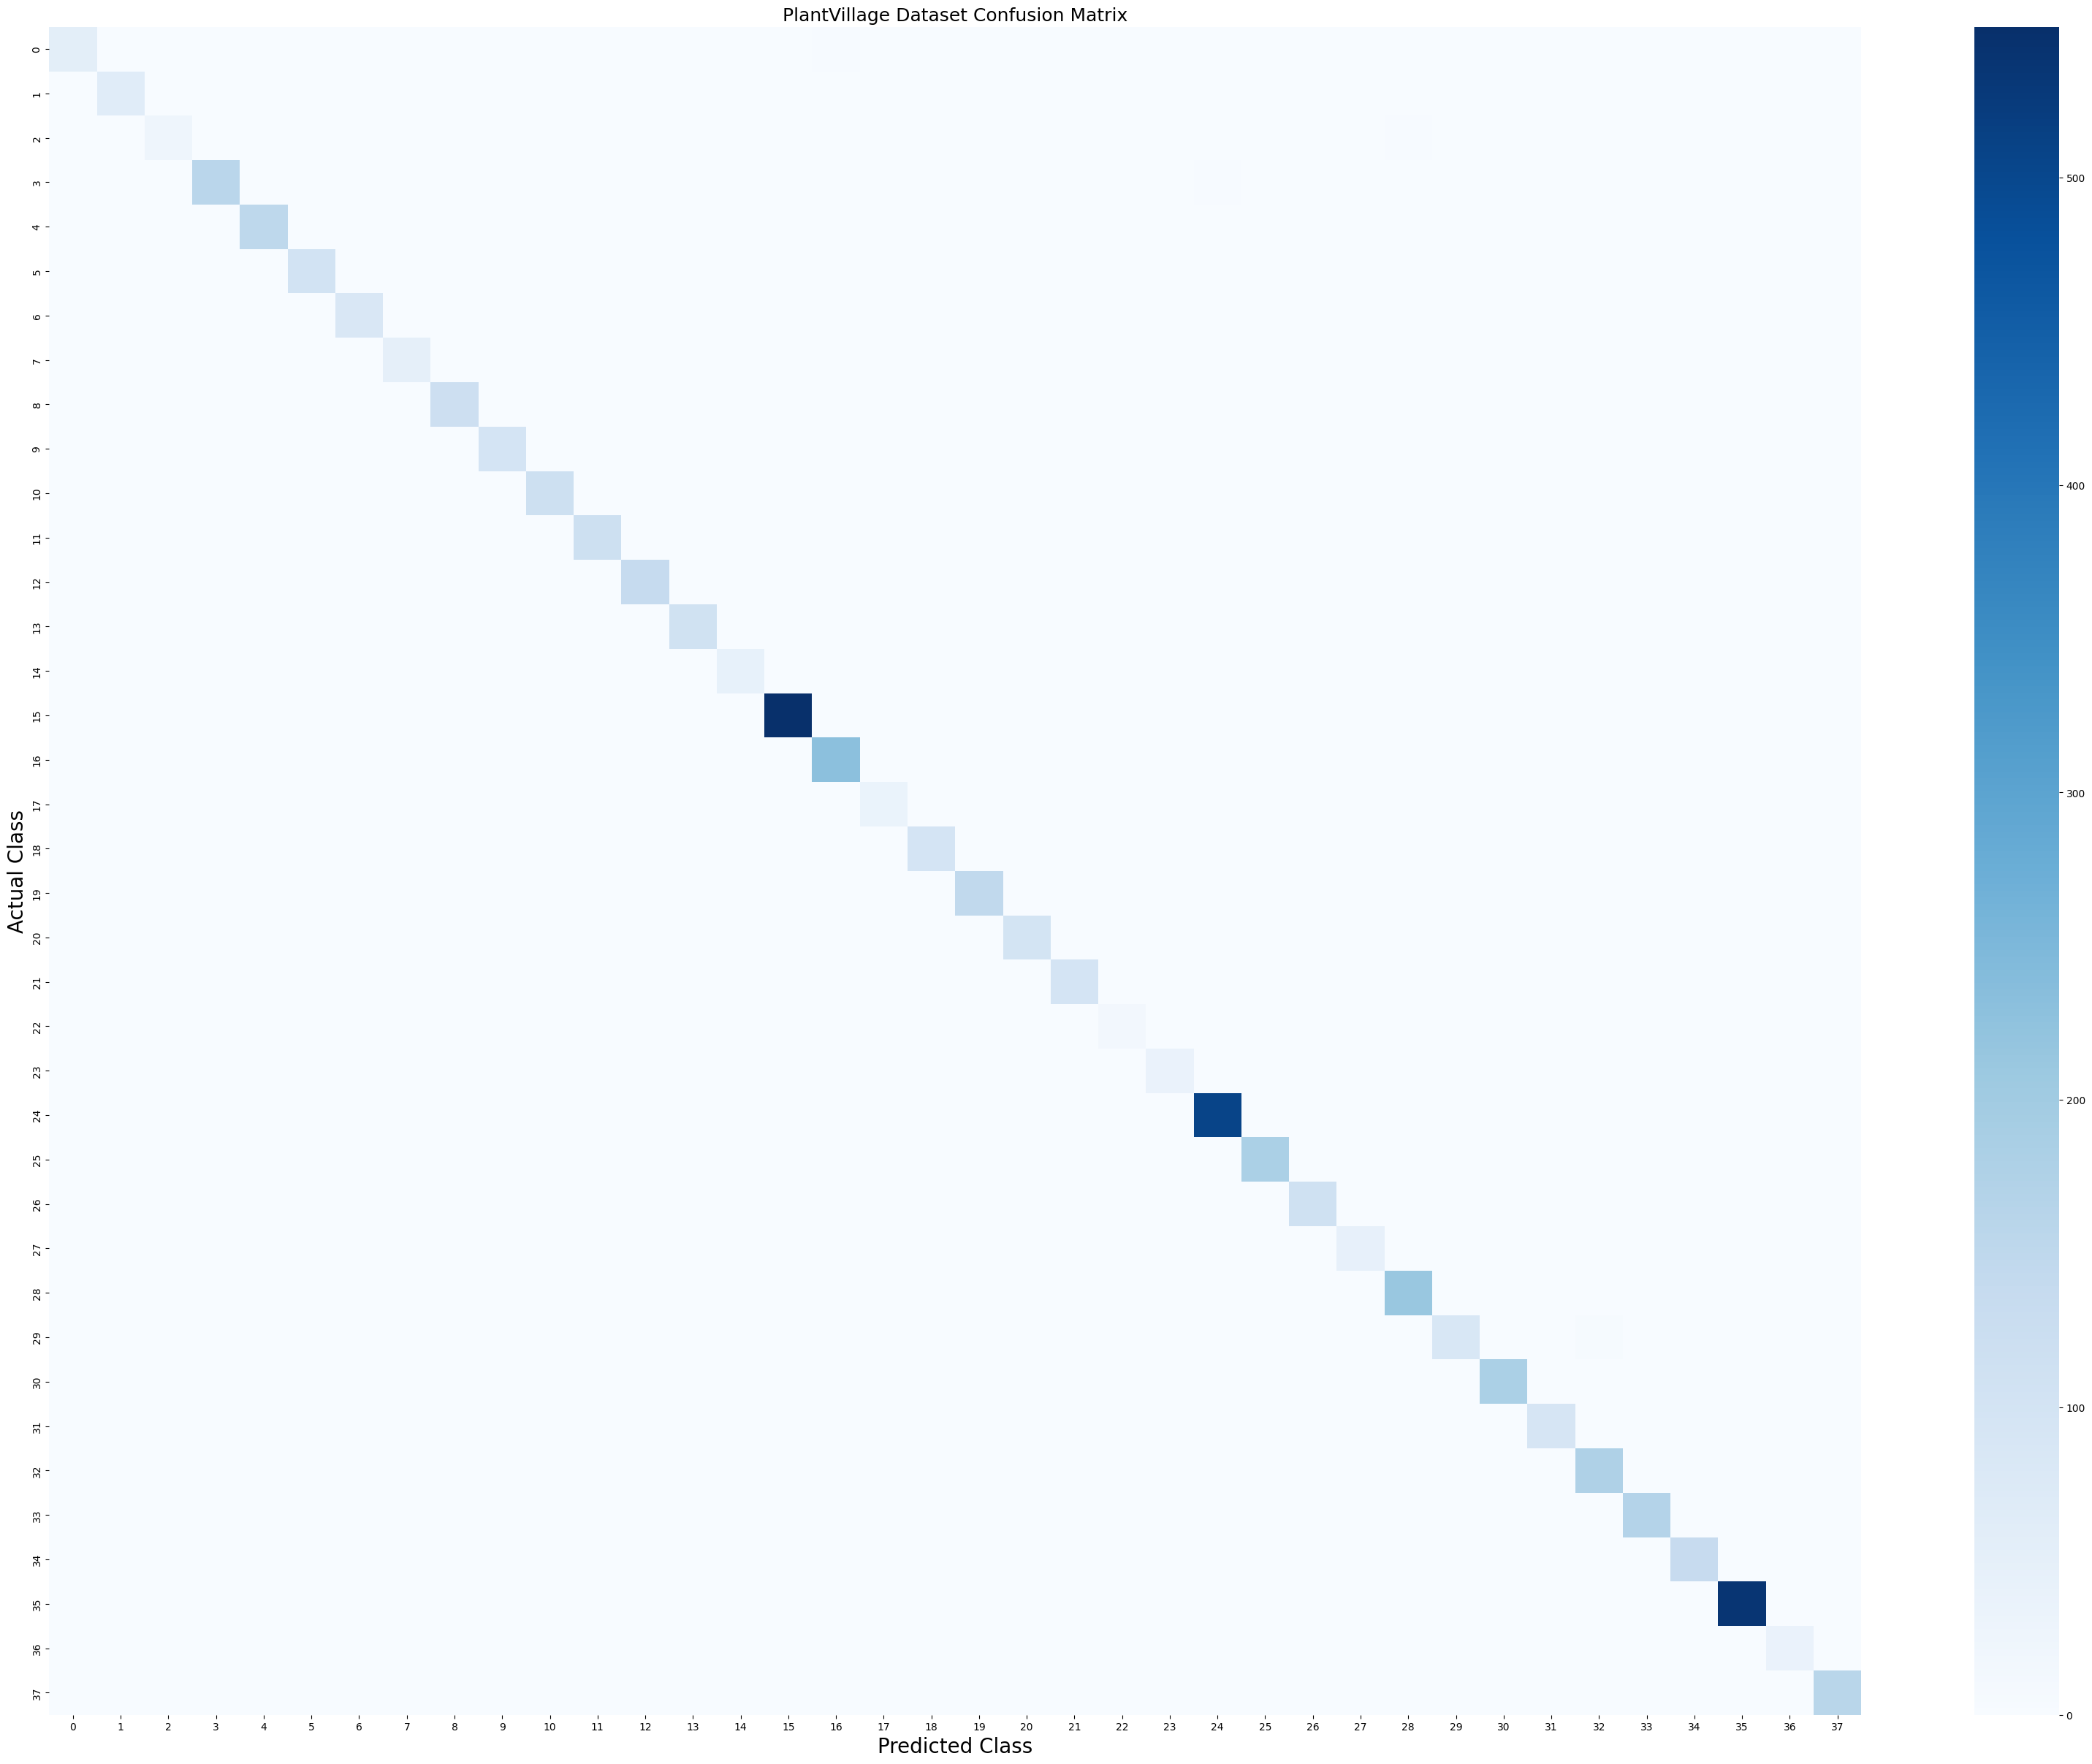

In [ ]:
# CONFUSION MATRIX VISUALIZATION
import matplotlib.pyplot as plt
import seaborn as sns

# Since there are 38 classes, a larger figure size is required to display cleanly
plt.figure(figsize=(40, 30))

# We disable annotations (annot=False) as displaying numbers for 38x38 cells makes the plot cluttered
sns.heatmap(cm, annot=False, cmap='Blues')

plt.xlabel("Predicted Class", fontsize=20)
plt.ylabel("Actual Class", fontsize=20)
plt.title("PlantVillage Dataset Confusion Matrix", fontsize=18)

plt.show()